# Where Does Home Field Matter Most: NFL or College Football?

**Part 2 of the project.** Part 1 ([`analysis.ipynb`](analysis.ipynb)) measured home field in the NFL. This notebook repeats it for college football and compares the two.

**Key idea:** college home games are often mismatches (big schools host small schools), so there are 3 groups:
1. **NFL**: every game from Part 1
2. **College, all FBS**: top division vs. top division
3. **College, conference only**: evenly matched opponents, the fair comparison used for the verdict

Steps: pull from the CollegeFootballData.com API → clean → load into Postgres (`cfb` schema + `compare` view) → SQL → statistics → charts.

## 1. Pull the data
Every regular-season college game 2015–2025 from `https://api.collegefootballdata.com/games` (one call per season). The free API key lives in `.env` as `CFBD_API_KEY` and is never printed. Column names are converted from camelCase to snake_case (`homeTeam` → `home_team`). The helper code is in [`cfb.py`](cfb.py).

The raw pull is saved to `data/`, so re-running the notebook doesn't call the API again.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
import cfb

os.makedirs("data", exist_ok=True)
RAW = "data/raw_cfb_games.csv"
if os.path.exists(RAW):
    raw = pd.read_csv(RAW, low_memory=False)
else:
    raw = cfb.pull_games(2015, 2025)
    raw.to_csv(RAW, index=False)
print(raw.shape)
raw.groupby("home_classification").size()   # FBS, FCS, Division II and III are all in the pull

(25301, 34)


home_classification
fbs    9061
fcs    6939
ii     4403
iii    4826
dtype: int64

## 2. Clean the data
| Rule | Why |
| --- | --- |
| Both teams FBS | Compare top division vs. top division (no FCS or lower-division visitors) |
| Drop neutral sites | Nobody is really "home" (bowl-style kickoff games, rivalry games at NFL stadiums) |
| Completed games only | Some 2020 games were cancelled |
| Drop ties | Not a win or a loss (rare since overtime came in) |

Same new columns as the NFL table (`home_win`, `margin`, `covid_season`) plus `conference_game` (1 = both teams in the same conference).

In [2]:
games = cfb.clean(raw)
print(f"{len(games):,} games, {games.home_team.nunique()} teams, {games.conference_game.sum():,} conference games")
games.groupby("season").agg(games=("game_id", "size"), conference=("conference_game", "sum")).T

7,646 games, 137 teams, 5,627 conference games


season,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
games,704,693,715,710,714,499,712,715,728,717,739
conference,508,510,521,514,515,440,515,516,535,516,537


## 3. Load into the database
College games go in their own `cfb` schema; the comparison view lives in a `compare` schema. `nfl.games` and the dashboard's other tables are not touched. The view is dropped first because it depends on `cfb.games`, then rebuilt from [`sql/05_create_league_view.sql`](sql/05_create_league_view.sql).

In [3]:
load_dotenv()
engine = create_engine(os.environ["DB_URL"])
with engine.begin() as conn:
    conn.execute(text("CREATE SCHEMA IF NOT EXISTS cfb"))
    conn.execute(text("DROP VIEW IF EXISTS compare.league_games"))
games.to_sql("games", engine, schema="cfb", if_exists="replace", index=False)
with engine.begin() as conn:
    conn.execute(text(open("sql/05_create_league_view.sql").read()))
pd.read_sql("SELECT league, COUNT(*) AS games FROM compare.league_games GROUP BY league ORDER BY league", engine)

,league,games
0,College (all FBS),7646
1,College (conference),5627
2,NFL,2837


## 4. Answer the questions with SQL

In [4]:
def run(file):
    with open(f"sql/{file}") as f:
        return pd.read_sql(f.read(), engine)

compare = run("06_league_compare.sql")
by_season = run("07_league_by_season.sql")
fans = run("08_league_fan_effect.sql")
compare

,league,games,home_win_pct,edge_over_50,avg_home_margin
0,College (all FBS),7646,58.6,8.6,4.3
1,College (conference),5627,55.7,5.7,2.4
2,NFL,2837,54.6,4.6,1.8


In [5]:
by_season.pivot(index="season", columns="league", values="home_win_pct")

league,College (all FBS),College (conference),NFL
season,,,
2015,56.5,53.3,53.8
2016,58.3,55.5,57.8
2017,58.0,54.5,57.0
2018,59.6,55.8,60.6
2019,60.2,58.1,52.0
2020,56.5,55.7,50.4
2021,58.4,56.1,51.1
2022,58.6,54.7,56.7
2023,58.4,56.6,55.8


In [6]:
fans

,league,normal_games,games_2020,normal_home_win_pct,home_win_pct_2020,drop_in_2020,pct_of_edge_lost
0,NFL,2585.0,252.0,55.0,50.4,4.7,92.0
1,College (conference),5187.0,440.0,55.7,55.7,0.0,0.0
2,College (all FBS),7147.0,499.0,58.7,56.5,2.2,25.0


## 5. Is it more than luck?
- **95% range** for each league's home win % (`proportion_confint`, Wilson method).
- **p-values** (`proportions_ztest`): NFL vs. college conference games, and 2020 vs. normal seasons in each league. Below 0.05 = unlikely to be luck.

In [7]:
rows = pd.read_sql("SELECT league, covid_season, home_win FROM compare.league_games", engine)

def ci(g):
    lo, hi = proportion_confint(g.sum(), len(g), method="wilson")
    return pd.Series({"games": len(g), "home_win_pct": 100 * g.mean(), "low_95": 100 * lo, "high_95": 100 * hi})

ranges = rows.groupby("league").home_win.apply(ci).unstack().round(1)
ranges

,games,home_win_pct,low_95,high_95
league,,,,
College (all FBS),7646.0,58.6,57.5,59.7
College (conference),5627.0,55.7,54.4,57.0
NFL,2837.0,54.6,52.8,56.5


In [8]:
def p_value(a, b):
    return proportions_ztest([a.sum(), b.sum()], [len(a), len(b)])[1]

league = {name: g for name, g in rows.groupby("league")}
tests = [("NFL vs. college conference", p_value(league["NFL"].home_win, league["College (conference)"].home_win))]
for name, g in league.items():
    tests.append((f"{name}: normal vs. 2020", p_value(g[g.covid_season == 0].home_win, g[g.covid_season == 1].home_win)))
pd.DataFrame(tests, columns=["test", "p_value"]).round(3)

,test,p_value
0,NFL vs. college conference,0.362
1,College (all FBS): normal vs. 2020,0.332
2,College (conference): normal vs. 2020,0.999
3,NFL: normal vs. 2020,0.157


## 6. Charts

In [9]:
BLUE, ORANGE, INK, MUTED, GRID = "#0B3D91", "#E69F00", "#1F2937", "#6B7280", "#E5E7EB"
plt.rcParams.update({"font.size": 11, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK})

def tidy(ax):
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(length=0)

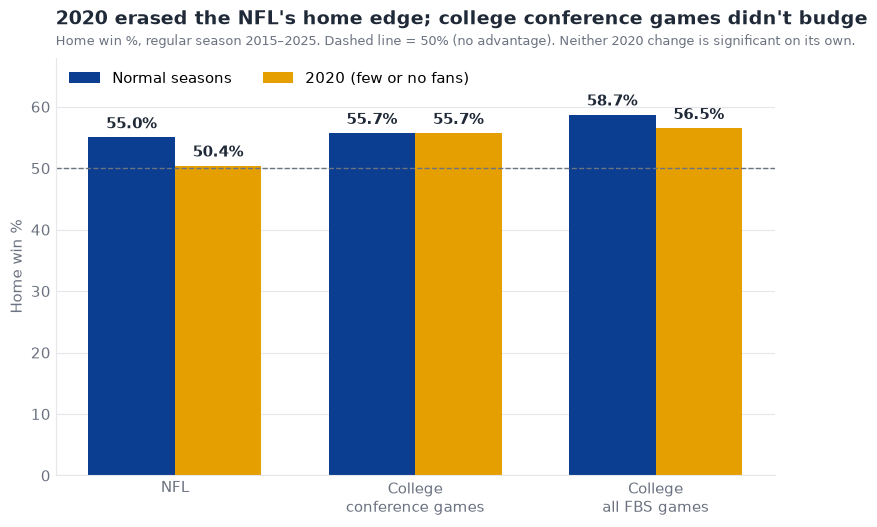

In [10]:
# Chart 8: normal seasons vs. 2020, by league (bars start at 0 so gaps aren't exaggerated)
order = ["NFL", "College (conference)", "College (all FBS)"]
f = fans.set_index("league").loc[order]
x = range(len(order)); w = 0.36
fig, ax = plt.subplots(figsize=(9, 5.4))
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
b1 = ax.bar([i - w / 2 for i in x], f.normal_home_win_pct, w, color=BLUE, label="Normal seasons")
b2 = ax.bar([i + w / 2 for i in x], f.home_win_pct_2020, w, color=ORANGE, label="2020 (few or no fans)")
for b in (b1, b2):
    ax.bar_label(b, fmt="%.1f%%", padding=4, color=INK, fontsize=11, fontweight="bold")
ax.axhline(50, ls="--", color=MUTED, lw=1)
ax.set_xticks(list(x), ["NFL", "College\nconference games", "College\nall FBS games"])
ax.set_ylim(0, 68); ax.set_ylabel("Home win %")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 1.0), ncol=2)
ax.set_title("2020 erased the NFL's home edge; college conference games didn't budge",
             loc="left", fontsize=13.5, fontweight="bold", pad=24)
ax.text(0, 1.03, "Home win %, regular season 2015–2025. Dashed line = 50% (no advantage). "
        "Neither 2020 change is significant on its own.", transform=ax.transAxes, color=MUTED, fontsize=9.5)
tidy(ax); plt.tight_layout(); plt.savefig("charts/08_league_fan_effect.png", dpi=200); plt.show()

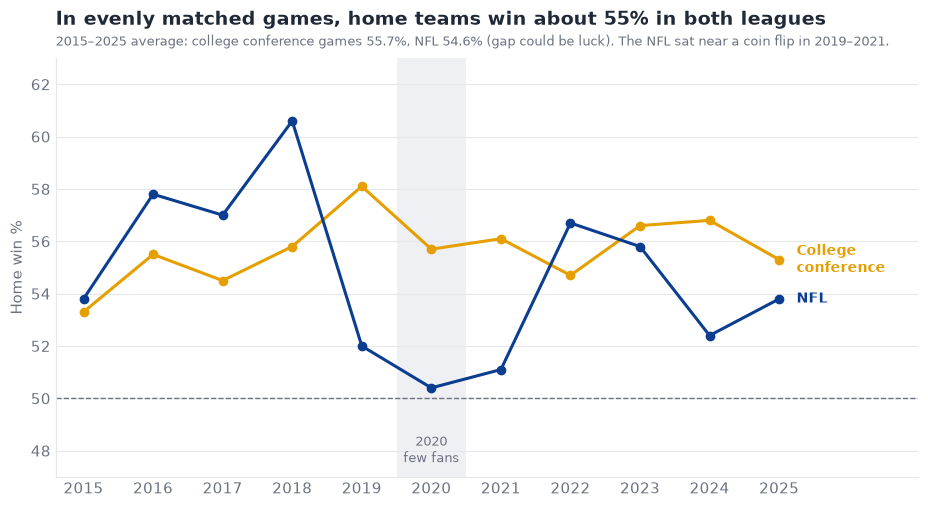

In [11]:
# Chart 9: home win % by season, NFL vs. college conference games, 2020 shaded
s = by_season.pivot(index="season", columns="league", values="home_win_pct")
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.axvspan(2019.5, 2020.5, color=GRID, alpha=0.6, lw=0)
ax.text(2020, 47.4, "2020\nfew fans", ha="center", va="bottom", color=MUTED, fontsize=9)
ax.axhline(50, ls="--", color=MUTED, lw=1)
ax.plot(s.index, s["College (conference)"], color=ORANGE, lw=2.2, marker="o", ms=6)
ax.plot(s.index, s["NFL"], color=BLUE, lw=2.2, marker="o", ms=6)
ax.text(2025.25, s.loc[2025, "College (conference)"], "College\nconference", color=ORANGE, va="center", fontsize=10, fontweight="bold")
ax.text(2025.25, s.loc[2025, "NFL"], "NFL", color=BLUE, va="center", fontsize=10, fontweight="bold")
ax.set_xlim(2014.6, 2027.0); ax.set_ylim(47, 63)
ax.set_xticks(range(2015, 2026)); ax.set_ylabel("Home win %")
ax.set_title("In evenly matched games, home teams win about 55% in both leagues",
             loc="left", fontsize=14, fontweight="bold", pad=24)
ax.text(0, 1.03, f"2015–2025 average: college conference games {compare.set_index('league').loc['College (conference)', 'home_win_pct']}%, "
        f"NFL {compare.set_index('league').loc['NFL', 'home_win_pct']}% (gap could be luck). The NFL sat near a coin flip in 2019–2021.",
        transform=ax.transAxes, color=MUTED, fontsize=9.5)
tidy(ax); plt.tight_layout(); plt.savefig("charts/09_league_by_season.png", dpi=200); plt.show()

## Findings
- **Evenly matched, home field is worth about the same in both leagues.** College conference home teams won **55.7%** (95% range 54.4–57.0) vs. **54.6%** in the NFL (52.8–56.5). The gap could easily be luck (p = 0.36).
- **College only looks bigger because of mismatches.** Counting every FBS game, college home teams won **58.6%** by **4.3 points**, because strong schools host weaker visitors.
- **2020 hit the NFL, not college conference games.** The NFL fell from **55.0%** to **50.4%** (about 90% of its edge gone); college conference games stayed at **55.7%**. Neither change is significant on its own (p = 0.16 and p ≈ 1.0); Part 1's strength-adjusted model does find the NFL drop significant (p = 0.006).

**Limitations**
- Some college stadiums had partial crowds in 2020 (often 20–25% capacity), while most NFL games had none, so "fans matter more in the NFL" can't be claimed outright.
- In 2020 most college teams played mostly conference games, so that season's schedule differs from normal years.
- Compare win %, not point margins: college games score more and have bigger blowouts.
- 2020 is one season, so its numbers are noisy.